
# Cafe Sales — Data Cleaning & Quality Analysis

**Python | Pandas | NumPy | Data Quality | Pytest**

## Project Overview

This project analyzes a dataset of 10,000 cafe sales
transactions containing missing values, invalid entries,
and inconsistent information.

The objective is to clean and validate the dataset
without inventing missing information.

### Key Results

- 10,000 transactions analyzed
- 1,951 documented value recoveries
- 340 documented placeholder normalizations
- 2,291 audited transformations
- 99.74% numerical completeness after cleaning
- 13 automated tests

### Methodology

1. Data exploration
2. Missing-value analysis
3. Data cleaning and recovery
4. Quality validation
5. Audit logging
6. Results and visualization


In [8]:

import os
import subprocess

repo_url = (
    "https://github.com/Facundosanchezz/"
    "cafe-sales-data-cleaning.git"
)

repo_dir = "/content/cafe-sales-data-cleaning"

if not os.path.exists(repo_dir):
    subprocess.run(
        ["git", "clone", repo_url, repo_dir],
        check=True
    )

os.chdir(repo_dir)

print("Directorio actual:", os.getcwd())


Directorio actual: /content/cafe-sales-data-cleaning


In [9]:

%pip install -q -r requirements.txt


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.calidad import validar_ventas, resumen_calidad
from src.limpieza import (
    normalizar_errores,
    recuperar_quantity,
    recuperar_quantity_con_auditoria
)

print("Módulos importados correctamente")


Módulos importados correctamente


In [11]:

df_demo = pd.DataFrame({
    "Transaction ID": [
        "TXN_001",
        "TXN_002",
        "TXN_003",
        "TXN_004",
        "TXN_005",
        "TXN_006"
    ],
    "Item": [
        "Coffee",
        "Tea",
        "ERROR",
        "Sandwich",
        "Coffee",
        "UNKNOWN"
    ],
    "Quantity": [
        2, None, 1, None, 3, None
    ],
    "Price Per Unit": [
        3.0, 2.5, 4.0, 5.0, 3.0, 2.0
    ],
    "Total Spent": [
        6.0, 5.0, 4.0, 12.0, 9.0, 8.0
    ]
})

display(df_demo)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent
0,TXN_001,Coffee,2.0,3.0,6.0
1,TXN_002,Tea,NaN,2.5,5.0
2,TXN_003,ERROR,1.0,4.0,4.0
3,TXN_004,Sandwich,NaN,5.0,12.0
4,TXN_005,Coffee,3.0,3.0,9.0
5,TXN_006,UNKNOWN,NaN,2.0,8.0


In [12]:

print("Dimensiones:", df_demo.shape)

print("\nValores faltantes:")
print(df_demo.isna().sum())

print("\nValores inválidos:")
for columna in ["Item"]:
    print(
        columna,
        df_demo[columna].isin(
            ["ERROR", "UNKNOWN"]
        ).sum()
    )


Dimensiones: (6, 5)

Valores faltantes:
Transaction ID    0
Item              0
Quantity          3
Price Per Unit    0
Total Spent       0
dtype: int64

Valores inválidos:
Item 2


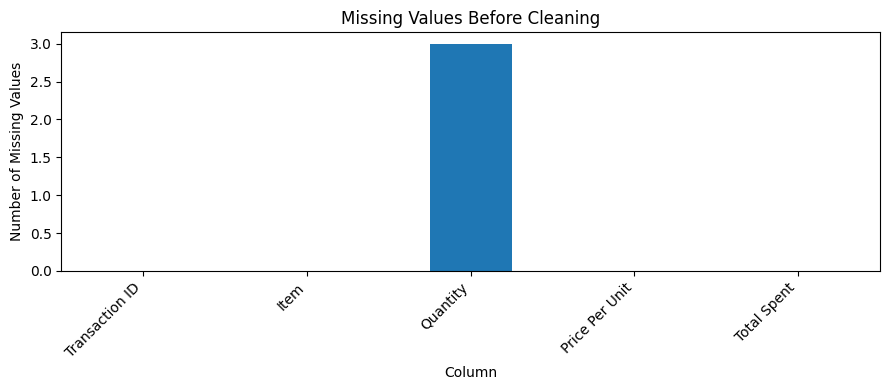

In [13]:

faltantes = df_demo.isna().sum()

faltantes.plot(
    kind="bar",
    figsize=(9, 4)
)

plt.title("Missing Values Before Cleaning")
plt.ylabel("Number of Missing Values")
plt.xlabel("Column")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [14]:

df_normalizado = normalizar_errores(
    df_demo,
    ["Item", "Quantity", "Price Per Unit", "Total Spent"]
)

df_recuperado, auditoria = (
    recuperar_quantity_con_auditoria(
        df_normalizado
    )
)

print("Datos después de la limpieza:")
display(df_recuperado)

print("Registro de auditoría:")
display(auditoria)


Datos después de la limpieza:


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent
0,TXN_001,Coffee,2.0,3.0,6.0
1,TXN_002,Tea,2.0,2.5,5.0
2,TXN_003,<NA>,1.0,4.0,4.0
3,TXN_004,Sandwich,NaN,5.0,12.0
4,TXN_005,Coffee,3.0,3.0,9.0
5,TXN_006,<NA>,4.0,2.0,8.0


Registro de auditoría:


,Transaction ID,Column,Original Value,New Value,Reason
0,TXN_002,Quantity,NaN,2.0,Calculated from Total Spent / Price Per Unit
1,TXN_006,Quantity,NaN,4.0,Calculated from Total Spent / Price Per Unit


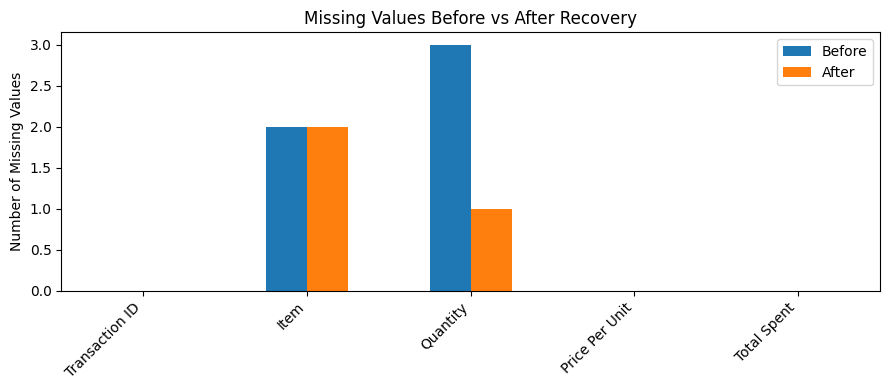

In [15]:

comparacion = pd.DataFrame({
    "Before": df_normalizado.isna().sum(),
    "After": df_recuperado.isna().sum()
})

comparacion.plot(
    kind="bar",
    figsize=(9, 4)
)

plt.title("Missing Values Before vs After Recovery")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
